# 111 src9 coverage: where the vase is never trained

src9's split (`src9/dataset.load_splits`, exactly what `src9/run.py` trains on): the wedge split, plus a held-out floor REGION for the **vase only**:
no trained sample has a vase pixel in it (multi-object scenes too), and `<box>/unseen-position` = single-vase positions with >= 50% of the vase's footprint inside.
Every other object still trains inside the square. FFT-glitch captures listed in `src9/exclude.csv` are dropped from train and eval.

Top row = vase CoMs, bottom row = every other object's CoMs (box fractions, row down, col right, as the masks; lasers on the row = 1 wall, bottom).
Colour = what the split does with that position: **train**, **eval** (held-out random positions of the trained splits, incl. OOD splits),
**unseen-position** (eval only), **dropped** (in no split: touches the square but < 50% inside). x = an excluded capture.
Grey shading = how often a TRAINED footprint of that row's objects covers each pixel.

In [1]:
import os, sys, csv
os.environ["TQDM_DISABLE"] = "1"
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from PIL import Image
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src9")); import dataset as D9

REGION, VASE = D9.REGION, D9.REGION_OBJECTS   # (row0, row1, col0, col1) box fractions; held out for these objects only
print(f"REGION = {REGION} for {VASE}, unseen-position >= {D9.REGION_EVAL} of the footprint inside")
samples, idx = D9.load_splits()
metas, dirs = list(samples.values()), list(samples)
bad = {(r["experiment"], r["sample_id"]) for r in csv.DictReader(open(D9.EXCLUDE))}
BOXES = {"gastro": "2026_09_27_gastronorm_four_objs", "plastic": "2026_10_05_green_plastic_four_objs", "cardboard": "2026_10_11_cardboard_four_objs"}

REGION = (0.4, 0.6, 0.3, 0.5) for ('vase',), unseen-position >= 0.5 of the footprint inside


2026_09_27_gastronorm_four_objs: 6155 samples


2026_10_05_green_plastic_four_objs: 5736 samples


2026_10_11_cardboard_four_objs: 7228 samples


split                                          samples    positions
-------------------------------------------  ---------  -----------
train                                            11219         3032
eval/gastro/vase                                   135           45
eval/gastro/candle                                 156           52
eval/gastro/cube                                   147           49
eval/gastro/cube-unseen-speaker-baseline           105           35
eval/gastro/cube-unseen-speaker-unseen              35           35
eval/gastro/soap-dispenser                         146           49
eval/gastro/cube-vase                               27            9
eval/gastro/two-cubes                               42           14
eval/gastro/cube-with-lid                           15            5
eval/gastro/cube-without-lid                        15            5
eval/gastro/cylinder-1000g                          27            9
eval/gastro/cylinder-500g                       

In [2]:
# role of each position: train / eval / unseen-position (a position's speakers all land on the same side)
roles = {}
for name, ids in idx.items():
    lab = "train" if name == "train" else "unseen-position" if name.endswith("unseen-position") else "eval"
    for i in ids: roles.setdefault(D9.key(metas[i]), lab)

def objects_at(d, h=128, w=128):
    # [(is_vase, (row, col) com as box fractions, (h,w) footprint)] from the instance masks image/smasks/<object><i>.npy
    out = []
    for f in sorted((d / "image/smasks").glob("*.npy")):
        m = np.load(f) > 0
        if not m.any(): continue
        r, c = np.nonzero(m)
        fp = np.asarray(Image.fromarray(m.astype(np.float32)).resize((w, h), Image.BOX))
        out.append((f.stem.rstrip("0123456789") in VASE, (r.mean() / m.shape[0], c.mean() / m.shape[1]), fp))
    return out

first, excluded = {}, {}   # one capture per position; positions with an excluded capture
for d, m in samples.items():
    if m.get("objects"): first.setdefault(D9.key(m), d)
    if (m["experiment"], m["sample_id"]) in bad: excluded[D9.key(m)] = excluded.get(D9.key(m), 0) + 1
objs = {k: objects_at(d) for k, d in first.items()}   # ~1 min: reads every position's instance masks once

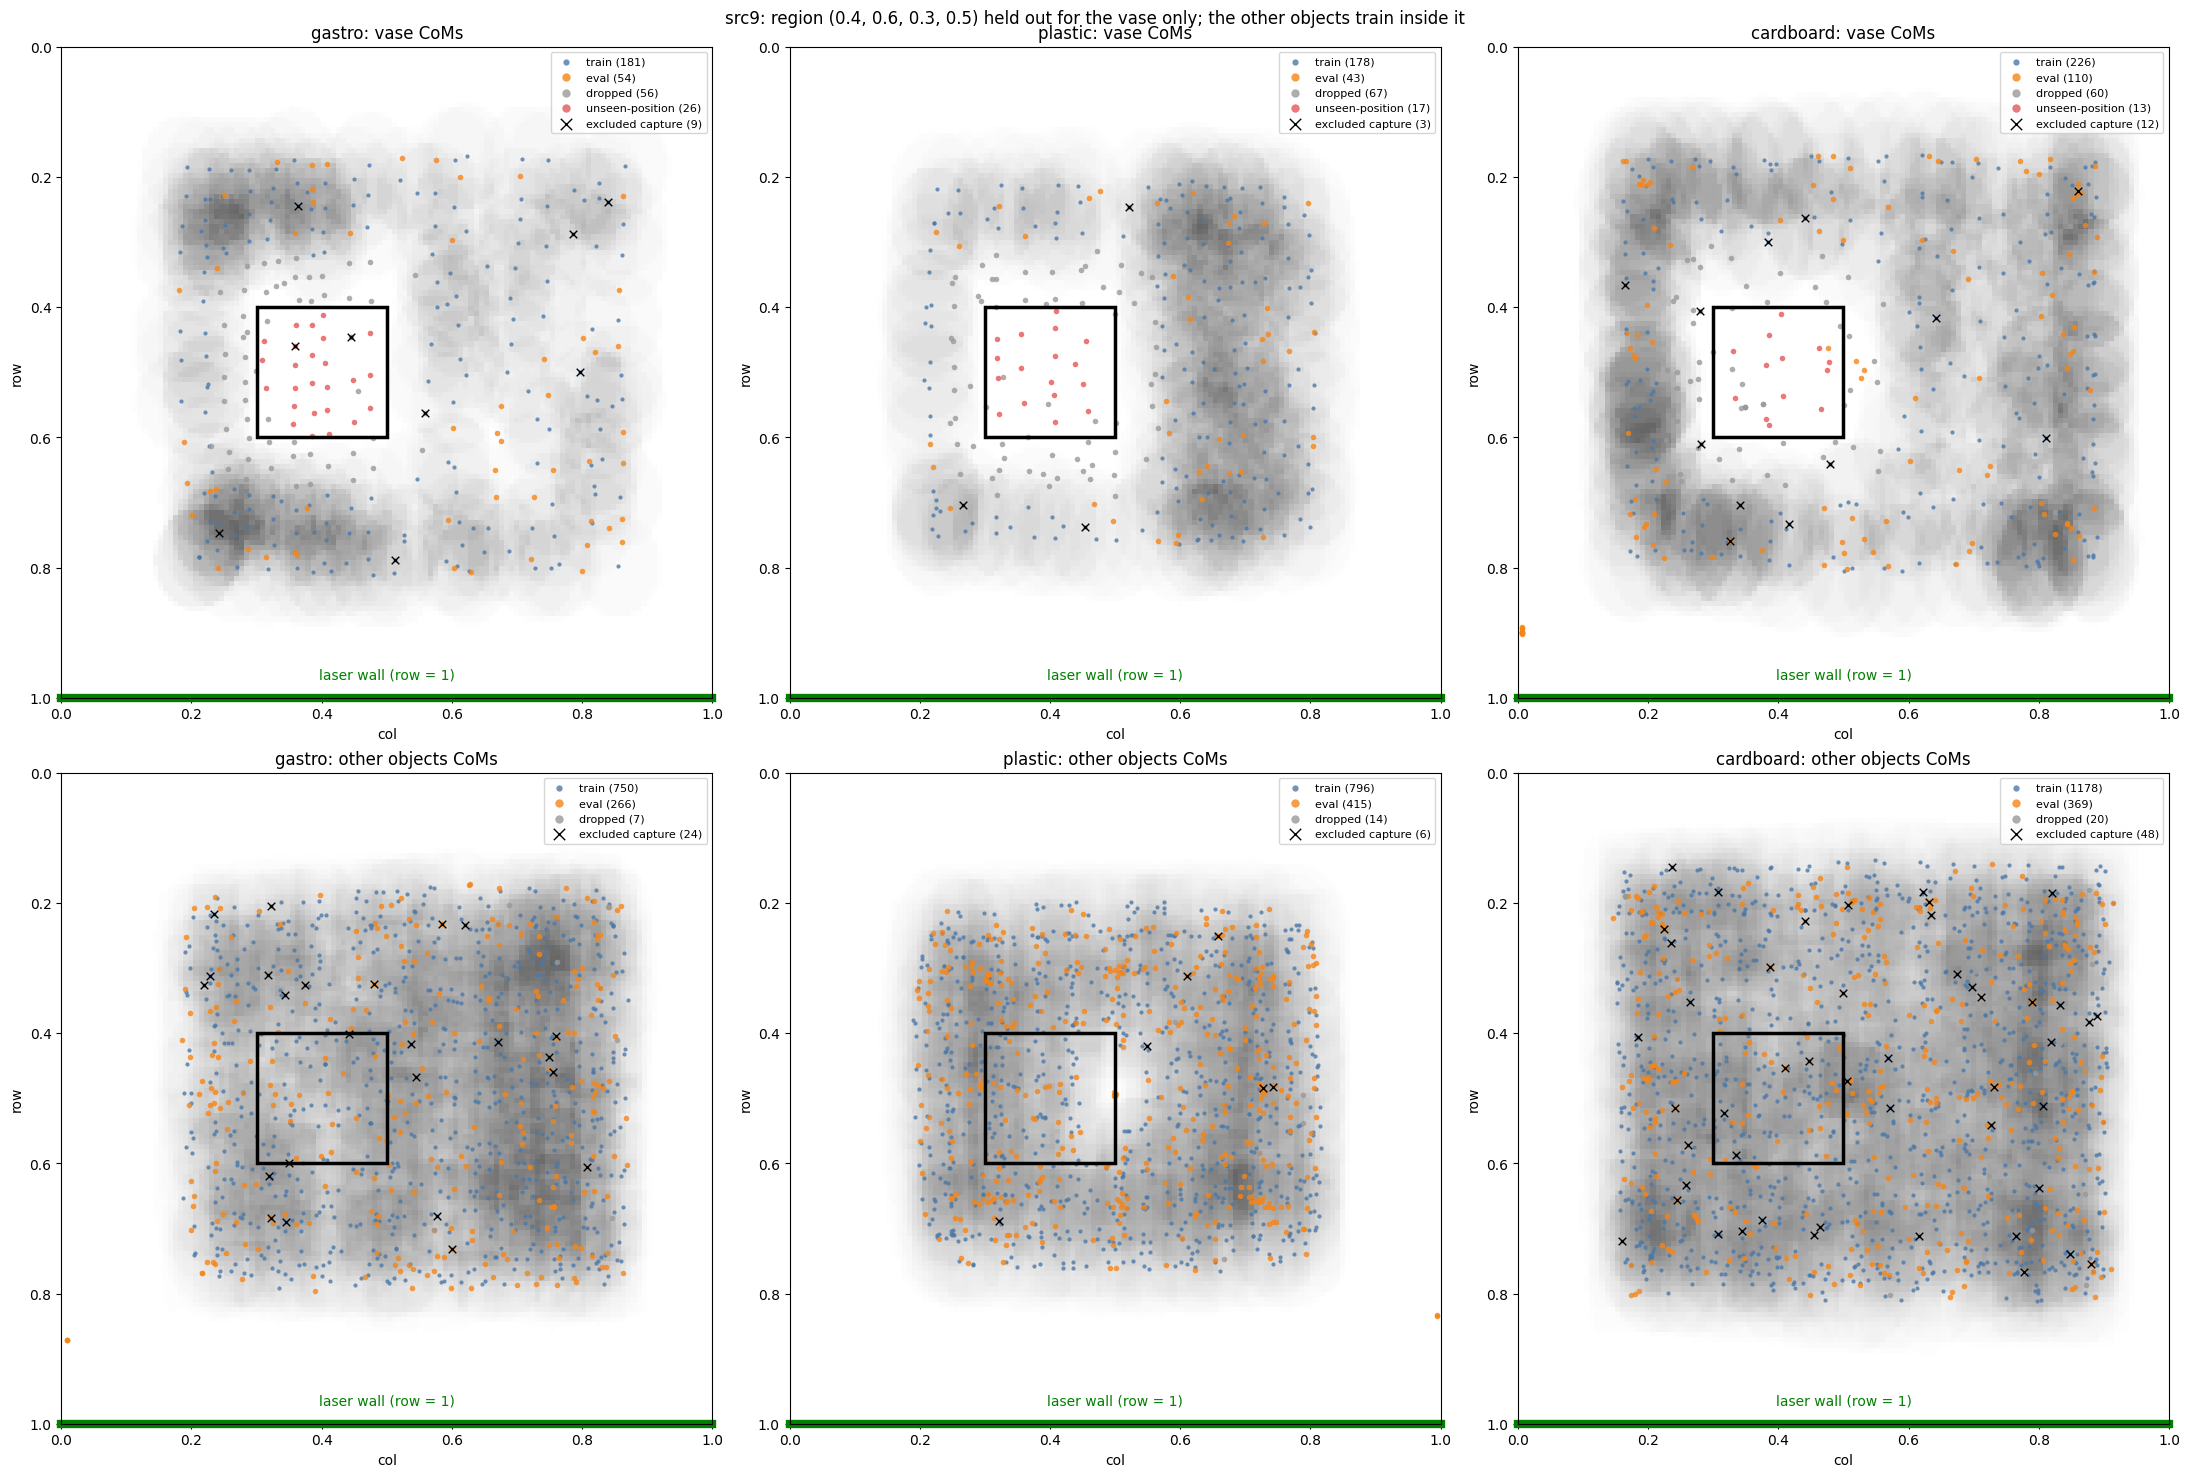

In [3]:
COL = {"train": "#4c78a8", "eval": "#f58518", "unseen-position": "#e45756", "dropped": "#999999"}

fig, axs = plt.subplots(2, 3, figsize=(22, 15))
for j, (box, exp) in enumerate(BOXES.items()):
    for i, vase in enumerate((True, False)):
        ax, pts, cov = axs[i, j], {lab: [] for lab in COL}, np.zeros((128, 128))
        xs = []
        for (e, p), os_ in objs.items():
            if e != exp: continue
            lab = roles.get((e, p), "dropped")
            for v, com, fp in os_:
                if v != vase: continue
                pts[lab].append(com)
                if lab == "train": cov += fp
                if (e, p) in excluded: xs.append(com)
        ax.imshow(cov, cmap="Greys", extent=(0, 1, 1, 0), alpha=0.6)
        for lab in ("train", "eval", "dropped", "unseen-position"):
            if pts[lab]: a = np.array(pts[lab]); ax.scatter(a[:, 1], a[:, 0], s=9 if lab == "train" else 16, c=COL[lab], lw=0, alpha=.8, label=f"{lab} ({len(a)})")
        if xs: a = np.array(xs); ax.scatter(a[:, 1], a[:, 0], marker="x", s=30, c="k", lw=1, label=f"excluded capture ({len(a)})")
        r0, r1, c0, c1 = REGION
        ax.add_patch(plt.Rectangle((c0, r0), c1 - c0, r1 - r0, fill=False, ec="k", lw=2.5))
        ax.axhline(1, color="green", lw=6, clip_on=False); ax.text(0.5, 0.975, "laser wall (row = 1)", color="green", ha="center", va="bottom")
        ax.set(xlim=(0, 1), ylim=(1, 0), aspect="equal", xlabel="col", ylabel="row", title=f"{box}: {'vase' if vase else 'other objects'} CoMs")
        ax.legend(loc="upper right", fontsize=8, markerscale=1.5)
fig.suptitle(f"src9: region {REGION} held out for the vase only; the other objects train inside it"); fig.tight_layout(); plt.show()

In [4]:
rows = []
for box, exp in BOXES.items():
    tr = [i for i in idx["train"] if metas[i]["experiment"] == exp]
    tv = [i for i in tr if set(metas[i].get("objects") or ()) & set(VASE)]
    un = idx.get(f"eval/{box}/unseen-position", [])
    pos = lambda ids: len({metas[i]["position_id"] for i in ids})
    rows.append(dict(box=box, train_positions=pos(tr), train_samples=len(tr), vase_train_positions=pos(tv), vase_train_samples=len(tv),
                     unseen_positions=pos(un), unseen_samples=len(un), excluded_samples=sum(n for (e, _), n in excluded.items() if e == exp)))
t = pd.DataFrame(rows).set_index("box"); t.loc["total"] = t.sum(); t

,train_positions,train_samples,vase_train_positions,vase_train_samples,unseen_positions,unseen_samples,excluded_samples
box,,,,,,,
gastro,852,2547,181,540,26,77,27
plastic,898,3587,178,710,17,68,9
cardboard,1282,5085,226,897,13,52,57
total,3032,11219,585,2147,56,197,93
